# Kaggle Data Science Survey Analysis

## Project goal

The goal of this project is to explore patterns among survey respondents in coding experience, programming-language use, preferred machine-learning framework, and compensation.

This is a descriptive analysis: the results show relationships in the survey sample, but they do not establish that a tool or level of experience causes a particular compensation amount.

## 1. Dataset overview

The dataset used here is `kaggle2021-short.csv`, a shortened copy of Kaggle 2021 survey data. Each row represents one respondent.

### Questions we will answer

1. How much coding experience do respondents report?
2. How widely are Python, R, and SQL used?
3. Which machine-learning frameworks are most common?
4. How does compensation vary across experience levels?
5. What limitations should be considered before interpreting the results?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

In [2]:
DATA_PATH = Path("../data/kaggle2021-short.csv")

df = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

df.head()

Dataset: ../data/kaggle2021-short.csv
Rows: 25,973
Columns: 6


,experience_coding,python_user,r_user,sql_user,most_used,compensation
0,6.1,True,False,True,Scikit-learn,124267
1,12.3,True,True,True,Scikit-learn,236889
2,2.2,True,False,False,NaN,74321
3,2.7,False,False,True,NaN,62593
4,1.2,True,False,False,Scikit-learn,36288


### Column definitions

- `experience_coding`: respondent's reported years of coding experience
- `python_user`: whether the respondent uses Python
- `r_user`: whether the respondent uses R
- `sql_user`: whether the respondent uses SQL
- `most_used`: the respondent's most-used listed machine-learning framework
- `compensation`: reported compensation value

In [3]:
print("Column information:")
df.info()

print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100).round(2),
})
print(missing)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
df.describe(include="all").T

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 25973 entries, 0 to 25972
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   experience_coding  25973 non-null  float64
 1   python_user        25973 non-null  bool   
 2   r_user             25973 non-null  bool   
 3   sql_user           25973 non-null  bool   
 4   most_used          16835 non-null  str    
 5   compensation       25973 non-null  int64  
dtypes: bool(3), float64(1), int64(1), str(1)
memory usage: 685.0 KB

Missing values:
                   missing_count  missing_percentage
experience_coding              0                0.00
python_user                    0                0.00
r_user                         0                0.00
sql_user                       0                0.00
most_used                   9138               35.18
compensation                   0                0.00

Duplicate rows: 54

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
experience_coding,25973.0,NaN,NaN,NaN,5.297232,6.898151,0.0,0.95,2.5,6.0,30.0
python_user,25973,2,True,21860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
r_user,25973,2,False,20638,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sql_user,25973,2,False,15216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
most_used,16835,4,Scikit-learn,7934,NaN,NaN,NaN,NaN,NaN,NaN,NaN
compensation,25973.0,NaN,NaN,NaN,53252.816964,80082.238508,0.0,7702.0,54010.0,67480.0,1492951.0


### Step 1 findings

- The dataset contains 25,973 rows and 6 columns.
- Python, R, SQL, and the framework preference fields have appropriate boolean/string representations.
- `most_used` has 9,138 missing values, representing 35.2% of rows.
- This missing data will not be treated as a zero or as a known framework choice.
- The compensation and experience columns require range and distribution checks before visualization.

## 2. Data cleaning and preparation

We keep the original data unchanged and create a separate `clean` DataFrame. Missing framework preferences remain visible as `No answer`, extreme compensation values are flagged but not removed, and experience is grouped for reporting.

In [4]:
numeric_columns = ["experience_coding", "compensation"]

print("Range checks:")
print(df[numeric_columns].agg(["min", "max"]))

print("\nNegative values:")
print({
    "experience_coding": int((df["experience_coding"] < 0).sum()),
    "compensation": int((df["compensation"] < 0).sum()),
})

print("\nCompensation percentiles:")
print(df["compensation"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

Range checks:
     experience_coding  compensation
min                0.0             0
max               30.0       1492951

Negative values:
{'experience_coding': 0, 'compensation': 0}

Compensation percentiles:
0.25      7702.00
0.50     54010.00
0.75     67480.00
0.90     81840.60
0.95    121838.80
0.99    276214.76
Name: compensation, dtype: float64


In [5]:
clean = df.copy()
clean["most_used"] = clean["most_used"].fillna("No answer")

experience_bins = [-np.inf, 2, 5, 10, 20, np.inf]
experience_labels = [
    "0–2 years",
    "Over 2–5 years",
    "Over 5–10 years",
    "Over 10–20 years",
    "Over 20 years",
]

clean["experience_group"] = pd.cut(
    clean["experience_coding"],
    bins=experience_bins,
    labels=experience_labels,
)

language_columns = ["python_user", "r_user", "sql_user"]
clean["language_count"] = clean[language_columns].sum(axis=1).astype(int)
clean["high_compensation"] = clean["compensation"] >= clean["compensation"].quantile(0.99)

print("Prepared rows:", len(clean))
print("Framework categories:", clean["most_used"].nunique())
print("Experience groups:")
print(clean["experience_group"].value_counts().sort_index())
print("\nFlagged high-compensation rows:", int(clean["high_compensation"].sum()))

Prepared rows: 25973
Framework categories: 5
Experience groups:
experience_group
0–2 years           11124
Over 2–5 years       7744
Over 5–10 years      3094
Over 10–20 years     2165
Over 20 years        1846
Name: count, dtype: int64

Flagged high-compensation rows: 260


### Cleaning decisions

- No invalid negative values require removal.
- No rows are deleted: 25,973 observations remain.
- The 35.2% missing `most_used` values remain identifiable as `No answer`.
- Compensation outliers are flagged rather than removed so later sensitivity analysis is possible.
- Unknown compensation units or survey-processing effects are documented limitations.

In [6]:
print("Original rows:", len(df))
print("Clean rows:", len(clean))
print("Rows removed:", len(df) - len(clean))

print("\nFramework values:")
print(clean["most_used"].value_counts(dropna=False))

clean[[
    "experience_coding",
    "experience_group",
    "python_user",
    "r_user",
    "sql_user",
    "language_count",
    "most_used",
    "compensation",
    "high_compensation",
]].head(10)

Original rows: 25973
Clean rows: 25973
Rows removed: 0

Framework values:
most_used
No answer       9138
Scikit-learn    7934
TensorFlow      3666
Keras           2790
PyTorch         2445
Name: count, dtype: int64


,experience_coding,experience_group,python_user,r_user,sql_user,language_count,most_used,compensation,high_compensation
0,6.1,Over 5–10 years,True,False,True,2,Scikit-learn,124267,False
1,12.3,Over 10–20 years,True,True,True,3,Scikit-learn,236889,False
2,2.2,Over 2–5 years,True,False,False,1,No answer,74321,False
3,2.7,Over 2–5 years,False,False,True,1,No answer,62593,False
4,1.2,0–2 years,True,False,False,1,Scikit-learn,36288,False
5,1.0,0–2 years,True,False,False,1,PyTorch,61302,False
6,1.8,0–2 years,False,False,False,0,No answer,68984,False
7,6.1,Over 5–10 years,True,False,False,1,TensorFlow,18858,False
8,4.5,Over 2–5 years,True,False,True,2,Scikit-learn,55418,False
9,1.1,0–2 years,True,False,True,2,TensorFlow,614,False


### Step 2 findings

- Missing framework values were preserved as a visible category.
- Experience was grouped into five ranges.
- A separate count of Python, R, and SQL usage was created.
- The top 1% of compensation values was flagged rather than deleted.
- The final cleaning stage preserved every respondent.

## 3. Core exploratory visualizations

These charts summarize the five central questions from Step 1. Every chart is paired with an interpretation and a limitation so that it is not overstated.

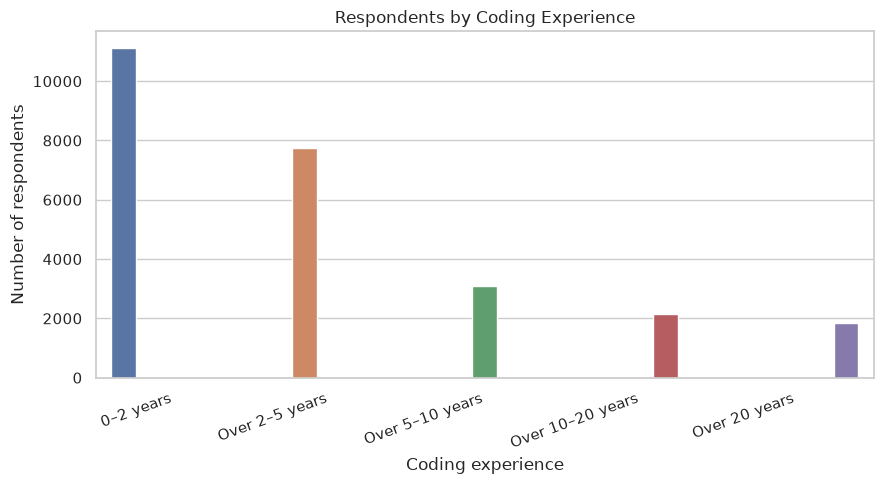

experience_group
0–2 years           11124
Over 2–5 years       7744
Over 5–10 years      3094
Over 10–20 years     2165
Over 20 years        1846
Name: count, dtype: int64


In [7]:
experience_counts = clean["experience_group"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=experience_counts.index, y=experience_counts.values, hue=experience_counts.index, legend=False, ax=ax)
ax.set_title("Respondents by Coding Experience")
ax.set_xlabel("Coding experience")
ax.set_ylabel("Number of respondents")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print(experience_counts)

**Observation:** The largest experience group can be identified directly from the chart and counts above.

**Limitation:** Survey experience is binned from a continuous response, so differences near category boundaries are not meaningful.

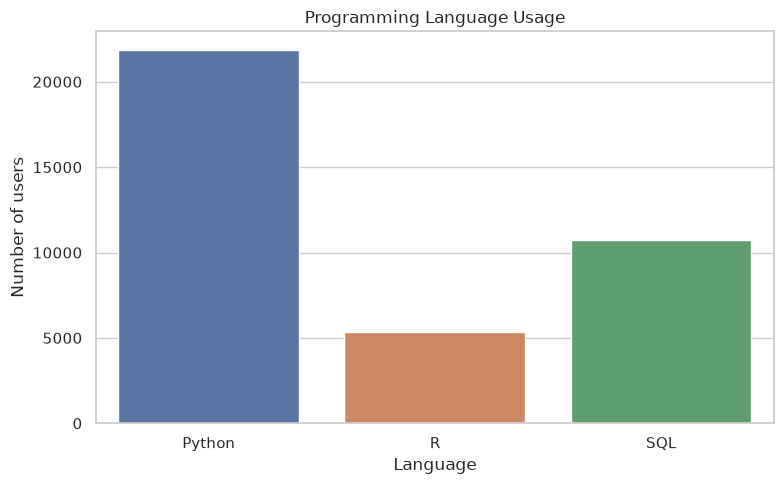

  language  users
0   Python  21860
1        R   5335
2      SQL  10757


In [8]:
language_counts = pd.DataFrame({
    "language": ["Python", "R", "SQL"],
    "users": [
        int(clean["python_user"].sum()),
        int(clean["r_user"].sum()),
        int(clean["sql_user"].sum()),
    ],
})

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=language_counts, x="language", y="users", hue="language", legend=False, ax=ax)
ax.set_title("Programming Language Usage")
ax.set_xlabel("Language")
ax.set_ylabel("Number of users")
plt.tight_layout()
plt.show()

print(language_counts)

**Observation:** Python, R, and SQL usage counts can be compared directly, although respondents may use more than one language.

**Limitation:** The separate language bars do not sum to the total number of respondents because use is not mutually exclusive.

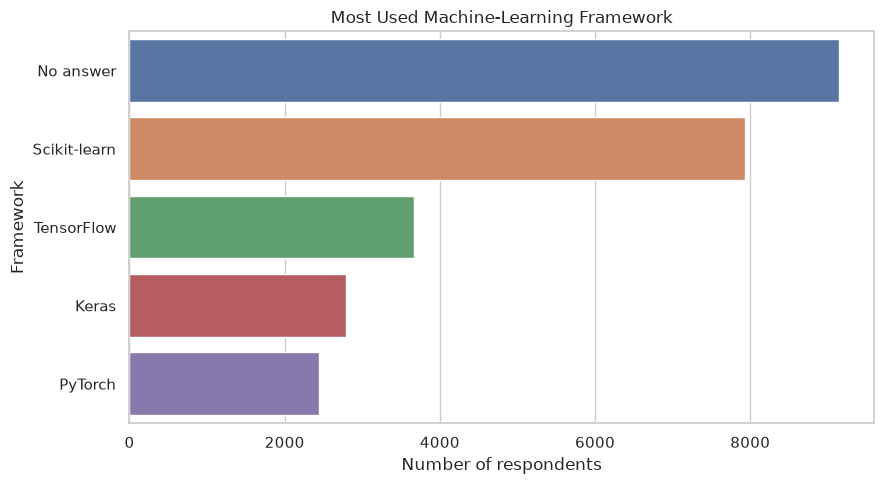

most_used
No answer       9138
Scikit-learn    7934
TensorFlow      3666
Keras           2790
PyTorch         2445
Name: count, dtype: int64


In [9]:
framework_counts = clean["most_used"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=framework_counts.values, y=framework_counts.index, hue=framework_counts.index, legend=False, ax=ax)
ax.set_title("Most Used Machine-Learning Framework")
ax.set_xlabel("Number of respondents")
ax.set_ylabel("Framework")
plt.tight_layout()
plt.show()

print(framework_counts)

**Observation:** Scikit-learn is likely to lead among reported frameworks, but the `No answer` category must be considered before ranking popularity.

**Limitation:** This field measures one reported framework choice and is missing for 35.2% of rows.

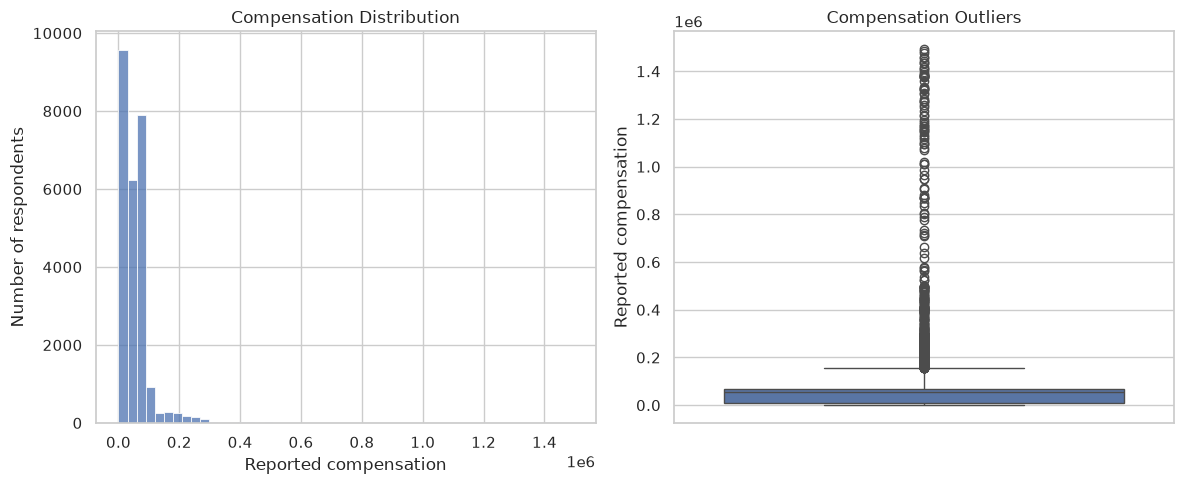

count    2.597300e+04
mean     5.325282e+04
std      8.008224e+04
min      0.000000e+00
25%      7.702000e+03
50%      5.401000e+04
75%      6.748000e+04
max      1.492951e+06
Name: compensation, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(clean["compensation"], bins=50, ax=axes[0])
axes[0].set_title("Compensation Distribution")
axes[0].set_xlabel("Reported compensation")
axes[0].set_ylabel("Number of respondents")

sns.boxplot(data=clean, y="compensation", ax=axes[1])
axes[1].set_title("Compensation Outliers")
axes[1].set_ylabel("Reported compensation")

plt.tight_layout()
plt.show()

print(clean["compensation"].describe())

**Observation:** Compensation is heavily right-skewed, with a median below the mean.

**Limitation:** The plotted values may combine unknown currency or reporting assumptions. Median and percentile summaries are safer than the mean for this field.

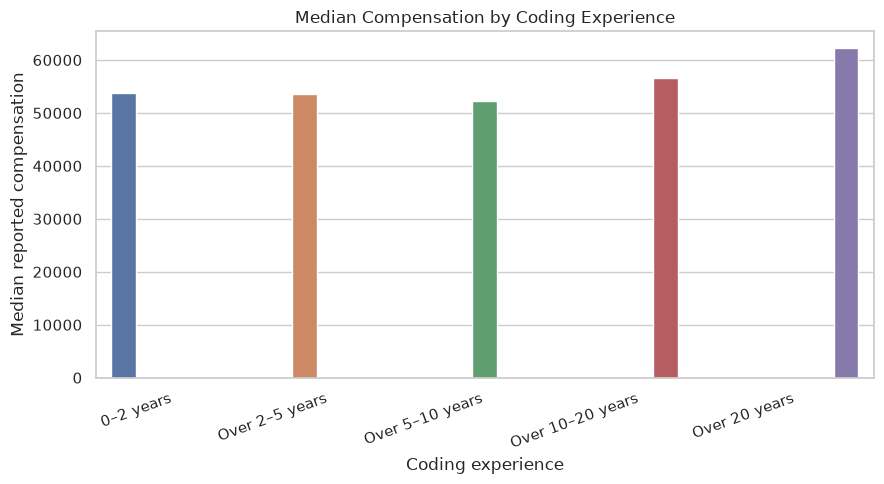

                  count   median      mean
experience_group                          
0–2 years         11124  53714.5  43769.84
Over 2–5 years     7744  53512.0  46905.73
Over 5–10 years    3094  52350.0  60126.36
Over 10–20 years   2165  56582.0  77422.84
Over 20 years      1846  62307.0  97156.22


In [11]:
experience_compensation = (
    clean.groupby("experience_group", observed=True)["compensation"]
    .agg(["count", "median", "mean"])
    .round(2)
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=experience_compensation.reset_index(),
    x="experience_group",
    y="median",
    hue="experience_group",
    legend=False,
    ax=ax,
)
ax.set_title("Median Compensation by Coding Experience")
ax.set_xlabel("Coding experience")
ax.set_ylabel("Median reported compensation")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print(experience_compensation)

**Observation:** The median bar chart shows the compensation pattern across broad experience groups; it is less distorted by extreme values than a mean chart.

**Limitation:** This is an association only. Country, role, industry, remote status, and inflation are not available in this shortened dataset.

### Step 3 findings

- The notebook now compares respondents across experience, language use, framework preference, and compensation.
- Median compensation is used for experience comparisons because it is robust to extreme values.
- Missing framework responses remain part of the count and are not incorrectly treated as framework choices.
- The data support descriptive patterns only, not causal conclusions.

## 4. Quantify relationships and test findings

This section converts the charts into measurable summaries. It also compares median compensation with and without the flagged top 1% to determine whether extreme values materially affect the conclusions.

In [12]:
experience_summary = (
    clean.groupby("experience_group", observed=True)["compensation"]
    .agg(respondents="size", median="median", mean="mean")
    .round(2)
)

print("Compensation by experience:")
print(experience_summary)

Compensation by experience:
                  respondents   median      mean
experience_group                                
0–2 years               11124  53714.5  43769.84
Over 2–5 years           7744  53512.0  46905.73
Over 5–10 years          3094  52350.0  60126.36
Over 10–20 years         2165  56582.0  77422.84
Over 20 years            1846  62307.0  97156.22


In [13]:
language_summary = pd.DataFrame({
    "language": ["Python", "R", "SQL"],
    "respondents_using": [
        int(clean["python_user"].sum()),
        int(clean["r_user"].sum()),
        int(clean["sql_user"].sum()),
    ],
    "median_compensation": [
        clean.loc[clean["python_user"], "compensation"].median(),
        clean.loc[clean["r_user"], "compensation"].median(),
        clean.loc[clean["sql_user"], "compensation"].median(),
    ],
})

language_summary["share_of_sample"] = (
    language_summary["respondents_using"] / len(clean)
).mul(100).round(2)

print(language_summary)

  language  respondents_using  median_compensation  share_of_sample
0   Python              21860              54772.5            84.16
1        R               5335              54576.0            20.54
2      SQL              10757              53039.0            41.42


In [14]:
framework_summary = (
    clean.groupby("most_used", observed=True)["compensation"]
    .agg(respondents="size", median="median", mean="mean")
    .sort_values("respondents", ascending=False)
    .round(2)
)

print("Compensation and usage by framework:")
print(framework_summary)

Compensation and usage by framework:
              respondents   median      mean
most_used                                   
No answer            9138  55410.0  50933.06
Scikit-learn         7934  53107.5  53616.56
TensorFlow           3666  53033.5  53390.68
Keras                2790  52211.5  53777.72
PyTorch              2445  53844.0  59936.71


In [15]:
without_top_1pct = clean.loc[~clean["high_compensation"]]

full_medians = clean.groupby("experience_group", observed=True)["compensation"].median()
trimmed_medians = without_top_1pct.groupby("experience_group", observed=True)["compensation"].median()

sensitivity = pd.DataFrame({
    "experience_group": full_medians.index,
    "full_sample_median": full_medians.values,
    "excluding_top_1pct_median": trimmed_medians.reindex(full_medians.index).values,
})

sensitivity["absolute_change"] = (
    sensitivity["full_sample_median"] - sensitivity["excluding_top_1pct_median"]
)

print(sensitivity)
print("\nFull-sample median:", clean["compensation"].median())
print("Excluding top 1% median:", without_top_1pct["compensation"].median())

   experience_group  full_sample_median  excluding_top_1pct_median  \
0         0–2 years             53714.5                    53654.0   
1    Over 2–5 years             53512.0                    53403.0   
2   Over 5–10 years             52350.0                    51851.0   
3  Over 10–20 years             56582.0                    55371.0   
4     Over 20 years             62307.0                    60321.0   

   absolute_change  
0             60.5  
1            109.0  
2            499.0  
3           1211.0  
4           1986.0  

Full-sample median: 54010.0
Excluding top 1% median: 53765.0


### Experience and compensation comparison

The following chart compares median compensation for the complete sample and after excluding the flagged top 1%. Agreement across the two series indicates that the experience pattern is not entirely driven by extreme values.

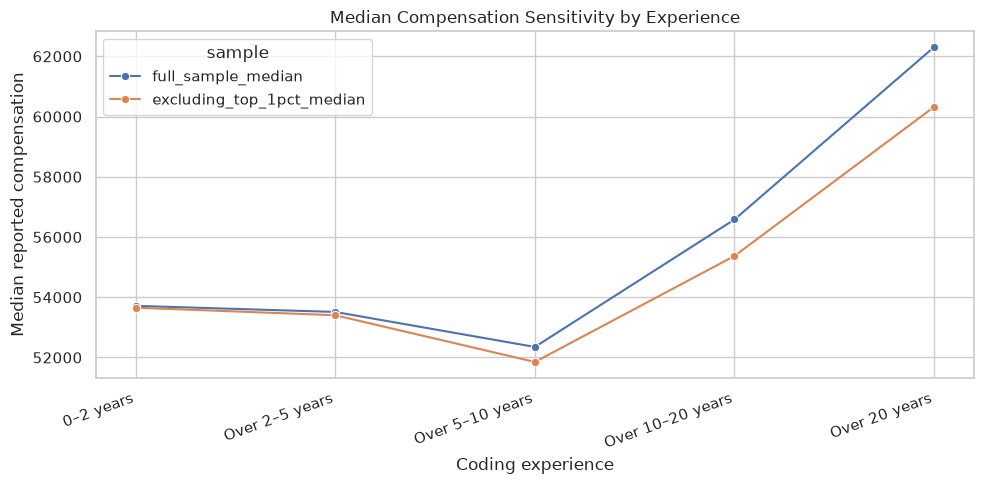

In [16]:
sensitivity_plot = sensitivity.melt(
    id_vars="experience_group",
    value_vars=["full_sample_median", "excluding_top_1pct_median"],
    var_name="sample",
    value_name="median_compensation",
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=sensitivity_plot,
    x="experience_group",
    y="median_compensation",
    hue="sample",
    marker="o",
    ax=ax,
)
ax.set_title("Median Compensation Sensitivity by Experience")
ax.set_xlabel("Coding experience")
ax.set_ylabel("Median reported compensation")
ax.ticklabel_format(axis="y", style="plain")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [17]:
spearman_experience_compensation = clean["experience_coding"].rank().corr(
    clean["compensation"].rank()
)

print(
    "Spearman correlation, experience vs. compensation:",
    round(spearman_experience_compensation, 4),
)
print(
    "Spearman correlation after excluding top 1%:",
    round(
        without_top_1pct["experience_coding"].rank().corr(
            without_top_1pct["compensation"].rank()
        ),
        4,
    ),
)

Spearman correlation, experience vs. compensation: 0.1455
Spearman correlation after excluding top 1%: 0.1328


### Step 4 findings

- The exact group sizes, medians, and means are now reported by experience and framework.
- Language shares are percentages of the full 25,973-row sample and remain non-exclusive.
- The top 1% sensitivity check reveals whether extreme compensation values materially change the experience pattern.
- Spearman correlation is used to assess rank association because compensation is not normally distributed.
- These values support descriptive relationships only; they do not isolate a causal effect.